# Kreditly — India repayment check (L&T Vehicle Loan Default)

**Goal.** Give Indian users an India-trained signal about repayment risk, to sit next to the published-lender-rules check.

**Data.** L&T Financial Services vehicle loans (Analytics Vidhya FinHack), 233,154 loans disbursed Aug–Oct 2018. Target = default on the **first EMI**.

**Honest limits.**
- Two-wheeler/vehicle loans, not personal loans.
- Predicts first-EMI default, **not loan approval**.
- No income column.
- We only use questions a user can answer, so lender-only columns (branch, dealer, asset cost, LTV) are left out. This costs accuracy (AUC ≈ 0.60 vs ≈ 0.66 with everything).

Run from the `notebooks/` folder. The data goes in `data/lt_vehicle_loan/train.csv` (git-ignored).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, shap
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split
from src.india_model import FEATURES, features_from_lt

raw = pd.read_csv(ROOT / "data/lt_vehicle_loan/train.csv")
X = features_from_lt(raw); y = raw["loan_default"]
print(raw.shape, "default rate:", round(y.mean(), 4))
X.describe().T.round(1)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(233154, 41) default rate: 0.2171


,count,mean,std,min,25%,50%,75%,max
bureau_score,233154.0,289.5,338.4,0.0,0.0,0.0,678.0,890.0
no_credit_history,233154.0,0.5,0.5,0.0,0.0,1.0,1.0,1.0
age,233154.0,34.5,9.8,18.0,26.4,32.7,41.4,69.1
self_employed,233154.0,0.5,0.5,0.0,0.0,1.0,1.0,1.0
employment_missing,233154.0,0.0,0.2,0.0,0.0,0.0,0.0,1.0
credit_history_months,233154.0,16.3,28.6,0.0,0.0,0.0,24.0,468.0
active_loans,233154.0,1.1,2.0,0.0,0.0,0.0,1.0,144.0
overdue_loans,233154.0,0.2,0.6,0.0,0.0,0.0,0.0,25.0
missed_emi_last_6m,233154.0,0.1,0.4,0.0,0.0,0.0,0.0,20.0
new_loans_last_6m,233154.0,0.4,1.0,0.0,0.0,0.0,0.0,35.0


## 1. Exploring the data
Default rate by bureau score band, and by missed EMIs / loan enquiries.

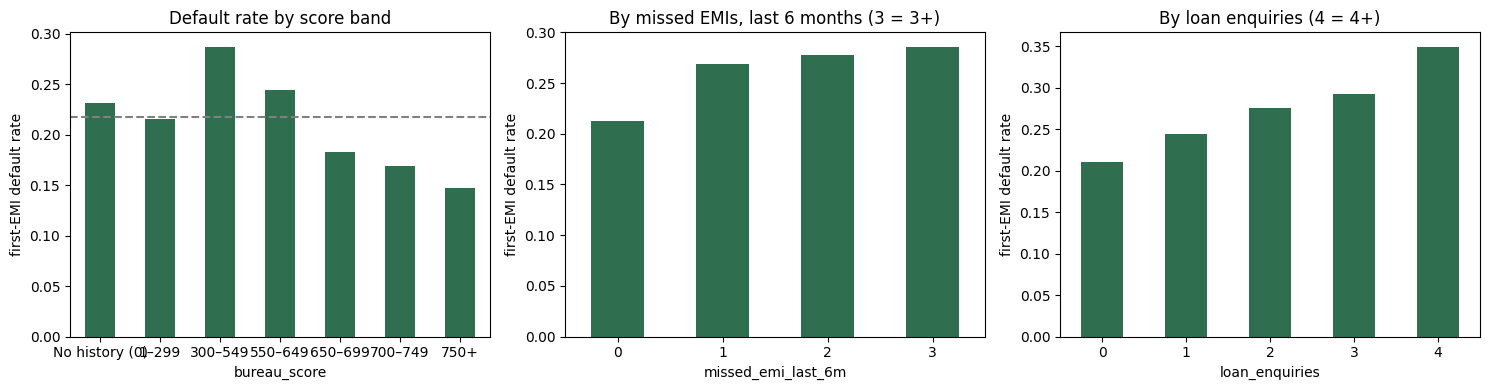

In [2]:
bands = pd.cut(X.bureau_score, [-1, 0, 299, 549, 649, 699, 749, 1000],
               labels=["No history (0)", "1–299", "300–549", "550–649", "650–699", "700–749", "750+"])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
y.groupby(bands, observed=True).mean().plot.bar(ax=ax[0], color="#2f6f4f"); ax[0].set_title("Default rate by score band"); ax[0].axhline(y.mean(), ls="--", c="gray")
y.groupby(X.missed_emi_last_6m.clip(upper=3)).mean().plot.bar(ax=ax[1], color="#2f6f4f"); ax[1].set_title("By missed EMIs, last 6 months (3 = 3+)")
y.groupby(X.loan_enquiries.clip(upper=4)).mean().plot.bar(ax=ax[2], color="#2f6f4f"); ax[2].set_title("By loan enquiries (4 = 4+)")
for a in ax: a.set_ylabel("first-EMI default rate"); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 2. Training
Training is in `notebooks/train_india_model.py` (run it once to create `models/india/`):
- 70/15/15 stratified split, `random_state=42`.
- Logistic Regression vs Random Forest vs XGBoost, with class weighting.
- XGBoost uses **monotonic constraints**: more missed EMIs, overdue loans, enquiries or new loans can never lower risk, so what-if answers stay sensible.
- Isotonic calibration is fitted on the validation split only.

In [3]:
m = json.loads((ROOT / "models/india/metrics.json").read_text())
pd.DataFrame(m["comparison"])

,model,validation_roc_auc,test_roc_auc
0,Logistic Regression,0.5731,0.5776
1,Random Forest,0.5945,0.5995
2,XGBoost,0.5931,0.5969


In [4]:
pd.Series(m["test_calibrated"], name="XGBoost (calibrated), test set")

roc_auc      0.5968
brier        0.1662
accuracy     0.4020
precision    0.2447
recall       0.8406
f1           0.3790
threshold    0.1875
Name: XGBoost (calibrated), test set, dtype: float64

## 3. Calibration and risk bands on the held-out test set

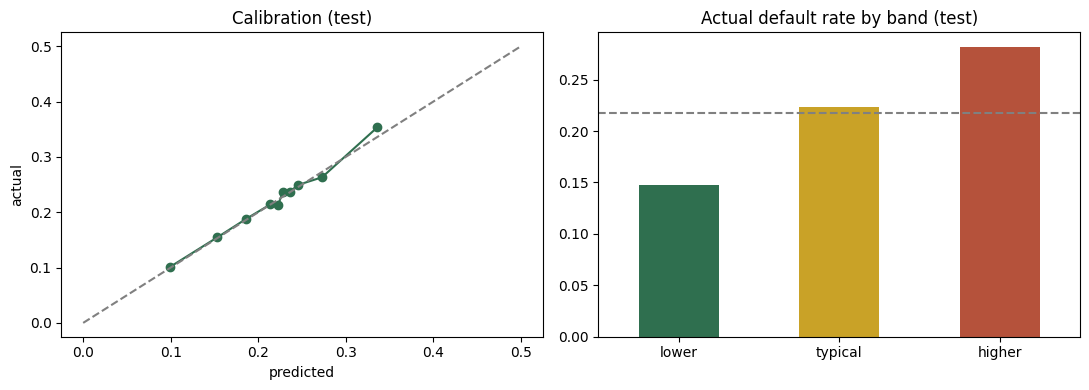

lower      0.148
typical    0.223
higher     0.282
dtype: float64

In [5]:
model = joblib.load(ROOT / "models/india/model.pkl"); cal = joblib.load(ROOT / "models/india/calibrator.pkl")
idx = np.arange(len(X))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=42)
va, te = train_test_split(tmp, test_size=0.50, stratify=y.iloc[tmp], random_state=42)
raw_te = model.predict_proba(X.iloc[te])[:, 1]; p_te = cal.predict(raw_te)
frac, mean = calibration_curve(y.iloc[te], p_te, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(mean, frac, "o-", c="#2f6f4f"); ax[0].plot([0, .5], [0, .5], "--", c="gray"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("actual"); ax[0].set_title("Calibration (test)")
b = m["bands"]; band = np.where(raw_te <= b["lower_max"], "lower", np.where(raw_te >= b["higher_min"], "higher", "typical"))
rates = pd.Series(y.iloc[te].values).groupby(band).mean().reindex(["lower", "typical", "higher"])
rates.plot.bar(ax=ax[1], color=["#2f6f4f", "#c9a227", "#b5523b"]); ax[1].axhline(m["base_rate"], ls="--", c="gray"); ax[1].set_title("Actual default rate by band (test)"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show(); rates.round(3)

## 4. What drives the model (SHAP)

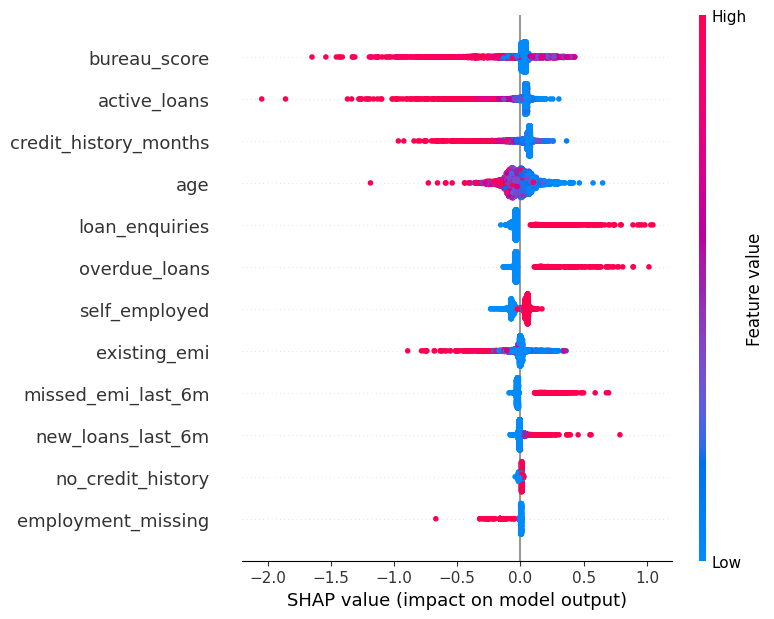

In [6]:
sample = X.iloc[te].sample(3000, random_state=42)
sv = shap.TreeExplainer(model).shap_values(sample)
shap.summary_plot(sv, sample, show=False); plt.tight_layout(); plt.show()

## 5. How Kreditly uses it
- It is shown as **“India repayment check”**: lower / about typical / higher than the average borrower in the data, plus the top 3 reasons.
- It never says approved or rejected. Approval comes from the lender-rules check and, in the end, from the lender.
- Unanswered optional questions are filled with medians and marked as *assumed*.
- AUC ≈ 0.60 is a weak but real signal: on held-out data, the "higher" band defaults almost twice as often as the "lower" band. We say this openly on the About page.

| | US model (LendingClub) | India model (L&T) |
|---|---|---|
| Loans | US personal loans | Indian vehicle loans |
| Target | Charged off over the loan's life | Missed first EMI |
| Test ROC-AUC | 0.69 | 0.60 |
| Used for | Secondary “repayment habits (US data)” card | Main repayment card |